# A sampled shell: establish access and closure independently

Can the same fixed atomic shell admit a small probe, enclose an intermediate
one and exclude a larger one from its finite hull? This study uses the exact
**72 atomic balls**, radii **1.7 Å**, already frozen in the historical case.
The generator's nominal 6 Å sphere and its small fixed-seed jitter describe
construction, not an exact continuum wall or cavity.

This notebook constructs independent references without importing TopoMT or
DFND. [dfnd.ipynb](dfnd.ipynb) reads its committed reference in a separate
kernel. Run either from this directory; neither executes an original provider,
contacts a server or overwrites an artifact. The old combined study remains
[historical.ipynb](historical.ipynb), with unchanged inputs and observations.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyunitwizard as puw
from IPython.display import Markdown, display
from matplotlib.patches import Circle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from pyunitwizard import QuantityRecord
from scipy.spatial import ConvexHull

DATA = Path('artifacts/native_study_v1')
protocol_bytes = (DATA / 'protocol.json').read_bytes()
protocol = json.loads(protocol_bytes)
input_bytes = Path(protocol['source_file']).read_bytes()
fixture = json.loads(input_bytes)
assert hashlib.sha256(input_bytes).hexdigest() == protocol['input_sha256']
for relative, digest in protocol['preserved_files'].items():
    assert hashlib.sha256(Path(relative).read_bytes()).hexdigest() == digest

def values(record, field, unit):
    quantity = QuantityRecord.from_dict(record).to_quantity(field=field, unit=unit)
    return np.asarray(puw.get_value(quantity, to_unit=unit))

def qrecord(data, unit, field):
    return QuantityRecord.from_quantity(puw.quantity(data, unit), field=field).to_dict()

def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(str(value) for value in row) + ' |' for row in rows]
    display(Markdown(chr(10).join(lines)))

coords = values(fixture['coordinates'], 'coordinates', 'angstroms')
radii = values(fixture['atom_radii'], 'atom_radii', 'angstroms')
origin = values(protocol['origin'], 'origin', 'angstroms')
direction = values(protocol['escape_witness']['direction'], 'direction', 'dimensionless')
atol = float(values(protocol['tolerances']['length_absolute'], 'length_absolute', 'angstroms'))
assert coords.shape == (72, 3) and radii.shape == (72,)
assert np.all(radii == 1.7)
np.testing.assert_allclose(np.linalg.norm(direction), 1, rtol=0, atol=1e-14)
table(['Input', 'Declared value'], [['Atoms', len(coords)], ['Atomic radius', '1.7 Å'],
    ['Primary probes', '0.05 / 1.4 / 5.0 Å'], ['Numerical reference margin', f'{atol:g} Å'],
    ['Geometry', 'Frozen nonperiodic coordinates; no regeneration or radius inference from PDB']])

| Input | Declared value |
| --- | --- |
| Atoms | 72 |
| Atomic radius | 1.7 Å |
| Primary probes | 0.05 / 1.4 / 5.0 Å |
| Numerical reference margin | 1e-06 Å |
| Geometry | Frozen nonperiodic coordinates; no regeneration or radius inference from PDB |

## Three proofs, three different questions

**Small-probe access.** For a unit direction d, the point on the ray
origin + t d (t ≥ 0) closest to atom i has
t_i = max(0, (a_i − origin)·d). The minimum clearance along the entire ray is
min_i (||a_i − origin − t_i d|| − r_i). A strictly positive margin above the
probe radius certifies this continuous all-atom path. The direction was
selected from fixed geometry-based candidates before fresh DFND execution;
a failed search would not prove that no path exists.

**An enclosed free origin.** Cover every convex-hull boundary triangle with
probe-expanded atomic balls, and separately verify that the origin is free
and strictly inside the hull. For a triangle with circumradius R_f and circle
center c, barycentric weights give

$$\sum_i \lambda_i\lVert p-a_i\rVert^2=R_f^2-\lVert p-c\rVert^2\le R_f^2.$$

Therefore some vertex lies within R_f of every point p on the triangle.
If min(r_i) + probe exceeds every R_f, the boundary is covered. A continuous
free path from the free origin to infinity would have to cross that blocked
boundary. This certifies at least one bounded probe-center component
containing the origin, with no exact global cavity-count claim.

**No free center anywhere in the finite hull.** Put all atom centers in an
origin-centered ball of radius R. Any point p in their convex hull is a
convex combination of those centers, so

$$\sum_i\lambda_i\lVert p-a_i\rVert^2
  =\sum_i\lambda_i\lVert a_i-origin\rVert^2-\lVert p-origin\rVert^2\le R^2.$$

Some atom center is consequently at distance at most R. If every expanded
atomic radius exceeds R, the whole finite hull is blocked to probe centers.
This is a sufficient bound, not an exact maximum-fit radius.

In [2]:
hull = ConvexHull(coords)
triangles = coords[hull.simplices]
a = np.linalg.norm(triangles[:, 0] - triangles[:, 1], axis=1)
b = np.linalg.norm(triangles[:, 1] - triangles[:, 2], axis=1)
c = np.linalg.norm(triangles[:, 2] - triangles[:, 0], axis=1)
areas = np.linalg.norm(np.cross(triangles[:, 1]-triangles[:, 0], triangles[:, 2]-triangles[:, 0]), axis=1)/2
face_cover = a*b*c/(4*areas)
delta = coords-origin
projected = np.maximum(delta@direction, 0)
per_atom_clearance = np.linalg.norm(delta-projected[:, None]*direction, axis=1)-radii
ray_clearance = float(per_atom_clearance.min())
center_clearance = float(np.min(np.linalg.norm(delta, axis=1)-radii))
signed_planes = hull.equations[:, :3]@origin + hull.equations[:, 3]
assert np.all(signed_planes < -atol)
hull_inradius = float(np.min(-signed_planes/np.linalg.norm(hull.equations[:, :3], axis=1)))
enclosing_radius = float(np.max(np.linalg.norm(delta, axis=1)))
terminal_distance = float(np.max(np.linalg.norm(delta, axis=1)+radii) + 1.05)
terminal = origin + terminal_distance*direction
assert np.any(hull.equations[:, :3]@terminal+hull.equations[:, 3] > atol)
assert ray_clearance > 0.05 + atol
assert radii.min()+1.4-face_cover.max() > atol
assert center_clearance > 1.4 + atol
assert radii.min()+5.0-enclosing_radius > atol
experiments = []
for declared in protocol['experiments']:
    probe = float(values(declared['probe_radius'], 'probe_radius', 'angstroms'))
    experiments.append({**declared, 'origin_free': bool(center_clearance-probe > atol),
        'wall_coverage_margin': qrecord(float(radii.min()+probe-face_cover.max()), 'angstroms', 'wall_coverage_margin'),
        'origin_margin': qrecord(center_clearance-probe, 'angstroms', 'origin_margin'),
        'full_hull_coverage_margin': qrecord(float(radii.min()+probe-enclosing_radius), 'angstroms', 'full_hull_coverage_margin')})
table(['Independent control', 'Evidence / margin'], [
    ['0.05 Å ray', f'Minimum all-atom clearance {ray_clearance:.9f} Å'],
    ['1.4 Å enclosure', f'Wall margin {radii.min()+1.4-face_cover.max():.9f} Å; free origin {center_clearance:.9f} Å'],
    ['5.0 Å exclusion', f'Full-hull coverage margin {radii.min()+5-enclosing_radius:.9f} Å'],
    ['0.2 Å historical anchor', 'Enclosure unresolved by these sufficient bounds']])

| Independent control | Evidence / margin |
| --- | --- |
| 0.05 Å ray | Minimum all-atom clearance 0.095285334 Å |
| 1.4 Å enclosure | Wall margin 1.070469277 Å; free origin 4.168062464 Å |
| 5.0 Å exclusion | Full-hull coverage margin 0.556631217 Å |
| 0.2 Å historical anchor | Enclosure unresolved by these sufficient bounds |

The principal controls have different reference strength: the small-probe
ray is an explicit access witness, the 1.4 Å proof certifies one enclosed
free region, and the large-probe bound excludes every center in the finite
hull. These do not establish general DFND path correctness or biological
transport.

At the older 0.2 Å anchor, the triangle-coverage margin is negative. That
result is **inconclusive**: it proves neither a leak nor closure. A fixed
candidate ray search also found no positive witness there; unsuccessful
search is not a no-path certificate. Its DFND result remains an observation.

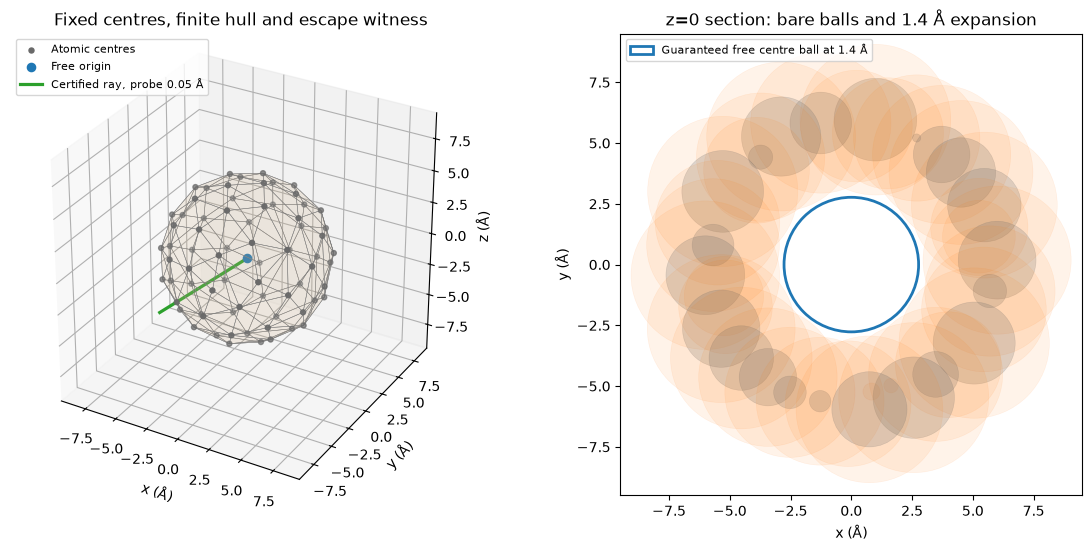

In [3]:
bare_radius = min(center_clearance, hull_inradius)
probe_center_radius = min(center_clearance-1.4, hull_inradius)
bare_lower = float(4*np.pi*bare_radius**3/3)
probe_center_lower = float(4*np.pi*probe_center_radius**3/3)
assert 0 < probe_center_lower < bare_lower < hull.volume
fig = plt.figure(figsize=(12, 5.4), constrained_layout=True)
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.add_collection3d(Poly3DCollection(triangles, facecolor='tan', edgecolor='grey', alpha=.11, linewidth=.35))
ax.scatter(*coords.T, s=13, color='dimgray', label='Atomic centres')
ax.scatter(*origin, s=35, color='tab:blue', label='Free origin')
segment = np.stack([origin, terminal])
ax.plot(*segment.T, color='tab:green', lw=2.3, label='Certified ray, probe 0.05 Å')
ax.set(xlim=(-9.5,9.5), ylim=(-9.5,9.5), zlim=(-9.5,9.5), xlabel='x (Å)', ylabel='y (Å)', zlabel='z (Å)', title='Fixed centres, finite hull and escape witness')
ax.set_box_aspect((1,1,1)); ax.legend(fontsize=8, loc='upper left')
ax = fig.add_subplot(1,2,2)
for point, radius in zip(coords, radii):
    for expanded,color,alpha in [(radius+1.4,'tab:orange',.09),(radius,'dimgray',.22)]:
        if abs(point[2]) < expanded:
            ax.add_patch(Circle(point[:2], np.sqrt(expanded**2-point[2]**2), facecolor=color, edgecolor=color, alpha=alpha, lw=.4))
ax.add_patch(Circle(origin[:2], probe_center_radius, fill=False, color='tab:blue', lw=2, label='Guaranteed free centre ball at 1.4 Å'))
ax.set(xlim=(-9.5,9.5), ylim=(-9.5,9.5), xlabel='x (Å)', ylabel='y (Å)', title='z=0 section: bare balls and 1.4 Å expansion', aspect='equal')
ax.legend(fontsize=8, loc='upper left')
plt.show()

The 3D hull is a boundary used by the proof, not the union-of-balls surface.
The section shows actual atomic-ball intersections with z=0 (grey) and their
1.4 Å expansions (orange). A 2D image alone would not certify the 3D wall.

The guaranteed **bare** empty ball gives a lower bound on total bare free
space restricted to the hull; the hull volume gives an upper bound. The
smaller blue centre-space ball uses expanded obstacles at 1.4 Å. These are
different volumes, and none is an exact central-cavity volume or a numerical
accuracy target for DFND's solvent estimate.

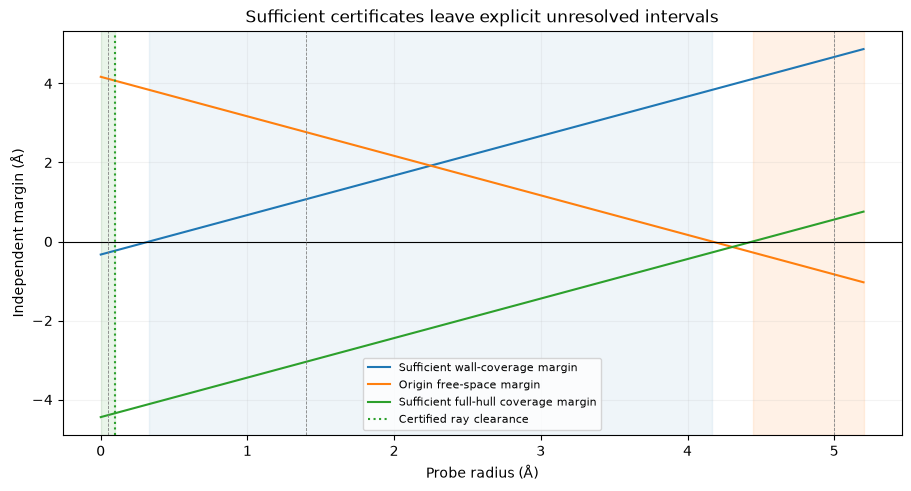

| Bound / definition | Volume (Å³) |
| --- | --- |
| Guaranteed bare free-space lower bound, finite hull | 303.313168 |
| Finite-hull upper bound, includes atomic-ball pieces | 839.875075 |
| Guaranteed free probe-centre ball at 1.4 Å | 88.841579 |

In [4]:
probes = np.linspace(0, 5.2, 105)
fig, ax = plt.subplots(figsize=(9,4.8), constrained_layout=True)
ax.axvspan(0, ray_clearance, color='tab:green', alpha=.10)
ax.axvspan(face_cover.max()-radii.min(), center_clearance, color='tab:blue', alpha=.07)
ax.axvspan(enclosing_radius-radii.min(), probes.max(), color='tab:orange', alpha=.10)
ax.plot(probes, radii.min()+probes-face_cover.max(), label='Sufficient wall-coverage margin')
ax.plot(probes, center_clearance-probes, label='Origin free-space margin')
ax.plot(probes, radii.min()+probes-enclosing_radius, label='Sufficient full-hull coverage margin')
ax.axhline(0,color='black',lw=.8)
ax.axvline(ray_clearance,color='tab:green',ls=':',label='Certified ray clearance')
for probe in (.05,1.4,5.): ax.axvline(probe,color='grey',ls='--',lw=.6)
ax.set(xlabel='Probe radius (Å)', ylabel='Independent margin (Å)', title='Sufficient certificates leave explicit unresolved intervals')
ax.legend(fontsize=8); ax.grid(alpha=.15)
plt.show()
table(['Bound / definition', 'Volume (Å³)'], [
    ['Guaranteed bare free-space lower bound, finite hull', f'{bare_lower:.6f}'],
    ['Finite-hull upper bound, includes atomic-ball pieces', f'{hull.volume:.6f}'],
    ['Guaranteed free probe-centre ball at 1.4 Å', f'{probe_center_lower:.6f}']])

The green band is certified by this ray, the blue band by the covered wall
plus free origin, and orange by full-hull coverage. The bounds are sufficient;
their endpoints are not established physical topology-transition values.

## Reference handoff

The report below is stored for the independent DFND stage. Rerunning displays
recomputed evidence without writing files. The old 0.2/1.4/5 Å anchors and
provider outcomes remain in the unchanged historical notebook. The declared
0.05 Å access control is an additional query on the same atoms, not regenerated
geometry or a retuned native parameter. Native volume precision #75 and the
full independent panel #76 remain separate.

In [5]:
reference = {
    'schema':'topomt.benchlab.closed-shell-reference/1', 'case_id':'closed_shell', 'case_version':1,
    'input_sha256':hashlib.sha256(input_bytes).hexdigest(),
    'protocol_sha256':hashlib.sha256(protocol_bytes).hexdigest(),
    'reference_checks':'passed', 'atom_count':len(coords), 'hull_face_count':len(triangles),
    'certificates':{
        'face_cover_radii':qrecord(face_cover,'angstroms','face_cover_radii'),
        'maximum_face_cover_radius':qrecord(float(face_cover.max()),'angstroms','maximum_face_cover_radius'),
        'center_clearance':qrecord(center_clearance,'angstroms','center_clearance'),
        'hull_inradius':qrecord(hull_inradius,'angstroms','hull_inradius'),
        'enclosing_radius':qrecord(enclosing_radius,'angstroms','enclosing_radius')},
    'escape_witness':{'origin':protocol['origin'],'direction':protocol['escape_witness']['direction'],
        'per_atom_clearance':qrecord(per_atom_clearance,'angstroms','per_atom_clearance'),
        'minimum_clearance':qrecord(ray_clearance,'angstroms','minimum_clearance'),
        'terminal_point':qrecord(terminal,'angstroms','terminal_point')},
    'experiments':experiments,
    'legacy_control':{**protocol['legacy_control'], 'wall_coverage_margin':qrecord(float(radii.min()+.2-face_cover.max()),'angstroms','wall_coverage_margin')},
    'volume_bounds':{'bare_free_lower':qrecord(bare_lower,'angstroms**3','bare_free_lower'),
        'finite_hull_upper':qrecord(float(hull.volume),'angstroms**3','finite_hull_upper'),
        'probe_center_ball_lower_at_1p4':qrecord(probe_center_lower,'angstroms**3','probe_center_ball_lower_at_1p4')},
    'tolerances':protocol['tolerances'], 'limits':protocol['scope_limits']}
display({'text/plain':json.dumps(reference,indent=2,allow_nan=False)},raw=True)

{
  "schema": "topomt.benchlab.closed-shell-reference/1",
  "case_id": "closed_shell",
  "case_version": 1,
  "input_sha256": "ef19995751b2df58c8b1556011f74fa4774e924b9cd499138b8741988b650157",
  "protocol_sha256": "533fd978a20725c36c355e01ad6ed1f05268d61b31bd62f4e77bbddfd8596925",
  "reference_checks": "passed",
  "atom_count": 72,
  "hull_face_count": 140,
  "certificates": {
    "face_cover_radii": {
      "manifest": {
        "format": "qrec/0.3",
        "field": "face_cover_radii",
        "unit": "angstrom",
        "si": {
          "factor": 1e-10,
          "offset": 0.0,
          "exponents": {
            "m": 1
          }
        },
        "dtype": "float64",
        "shape": [
          140
        ],
        "blocks": [
          140
        ]
      },
      "values": [
        1.6713909176138404,
        1.7778250500377482,
        1.6966372581289133,
        1.7351990445215542,
        1.442205344753868,
        1.5243671231011016,
        1.5788817110658586,
     